In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np

from data import load_data, get_minibatch
from utils import check_norm, plot_distribution, check_minibatch_len
from main import run_MLP, predict_mlp, run_conv_naive
from evaluation import accuracy
from grad_check import grad_check
from layers import SoftmaxCrossEntropy

data_train_path = Path('../data/fashion-mnist_train.csv')
data_test_path = Path('../data/fashion-mnist_test.csv')

labels_dict = {0: 'T-shirt/top', 1: 'Trousers', 2: 'Pullover', 
               3: 'Dress', 4: 'Coat', 5: 'Sandal', 6: 'Shirt', 
               7: 'Sneaker', 8: 'Bag', 9: 'Ankle Boot'}

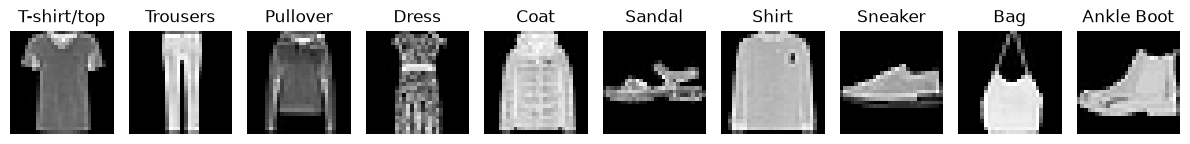

In [2]:


X_preview1, X_preview2, X_preview3, Y_preview1, Y_preview2, Y_preview3 = load_data(data_train_path, data_test_path, dtype='float64')
labels = np.argmax(Y_preview1, axis=1)
classes, idx = np.unique(labels, return_index=True)

fig, ax = plt.subplots(1, 10, figsize=(12, 8))


for i in range(10):
    ax[i].imshow(X_preview1[idx[i]], cmap='gray')
    ax[i].axis('off')
    ax[i].set_title(labels_dict[classes[i]])

plt.tight_layout()
plt.show()



In [3]:
check_norm(X_preview1)

mean: 0.0, std: 1.0


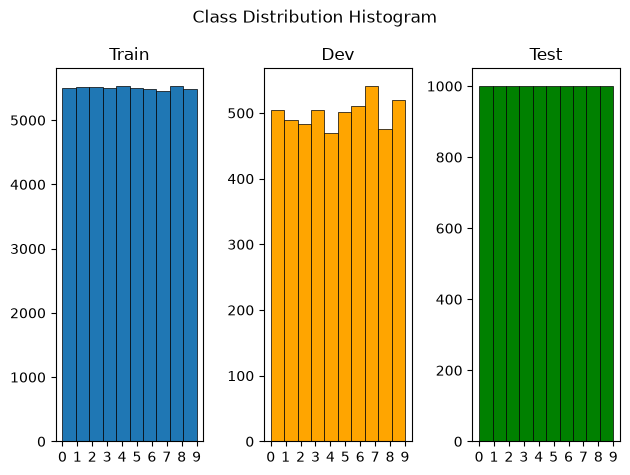

In [4]:
fig, ax = plt.subplots(1, 3)
fig.suptitle('Class Distribution Histogram')
plot_distribution(Y_preview1, Y_preview2, Y_preview3, ax)
plt.tight_layout()
plt.show()

In [5]:
m = len(X_preview1)
minibatch_loader = get_minibatch(X_preview1, Y_preview1, size=64)
check_minibatch_len(minibatch_loader, m)

All tests passed


In [6]:
rng = np.random.default_rng(seed=123)

model_mlp = run_MLP(X_preview1, Y_preview1, X_preview2, Y_preview2, 
             rng=rng, lr=1e-2, batch_size=64, max_epochs=10)

Epoch: 0, loss: 0.491309, accuracy train: 0.824, accuracy dev: 0.824
Epoch: 1, loss: 0.433758, accuracy train: 0.845, accuracy dev: 0.846
Epoch: 2, loss: 0.4104, accuracy train: 0.853, accuracy dev: 0.849
Epoch: 3, loss: 0.386024, accuracy train: 0.861, accuracy dev: 0.859
Epoch: 4, loss: 0.380027, accuracy train: 0.864, accuracy dev: 0.863
Epoch: 5, loss: 0.357741, accuracy train: 0.871, accuracy dev: 0.869
Epoch: 6, loss: 0.344063, accuracy train: 0.877, accuracy dev: 0.872
Epoch: 7, loss: 0.340297, accuracy train: 0.877, accuracy dev: 0.872
Epoch: 8, loss: 0.333255, accuracy train: 0.881, accuracy dev: 0.875
Epoch: 9, loss: 0.329247, accuracy train: 0.881, accuracy dev: 0.877


T-shirt/top


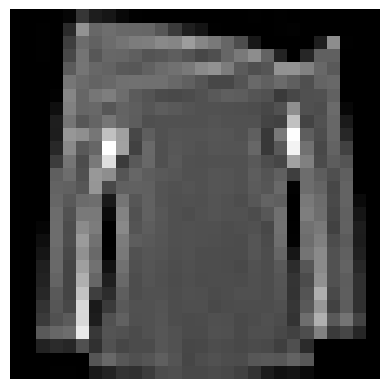

In [7]:
plt.imshow(X_preview2[0], cmap='gray')
plt.axis('off')
print(labels_dict[predict_mlp(X_preview2[0])])

In [14]:
model_conv_naive = run_conv_naive(X_preview1[:1000], Y_preview1[:1000], X_preview2[:200], Y_preview2[:200], rng=rng, lr=1e-2, batch_size=32, max_epochs=3)

Epoch: 0, loss: 1.337228, accuracy train: 0.549, accuracy dev: 0.495
Epoch: 1, loss: 0.661635, accuracy train: 0.772, accuracy dev: 0.67
Epoch: 2, loss: 0.51429, accuracy train: 0.827, accuracy dev: 0.72


In [9]:
grad_check(model_conv_naive, SoftmaxCrossEntropy(), X_preview2[:10], Y_preview2[:10], eps=1e-7, n_samples=-1, rng=rng)

{'W conv, layer: 0, shape: (3, 3, 1, 8)': np.float64(1.2280545701209803e-08),
 'b, layer: 1, shape: (8,)': np.float64(1.3685034819199877e-08),
 'W, layer: 2, shape: (6272, 10)': np.float64(9.283906997840014e-09),
 'b, layer: 3, shape: (10,)': np.float64(7.4271900157796285e-09)}

In [10]:
model_conv_naive.layers